In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
file_id = '10POMOPa2AKdGzvUWK3kKvV-eDwhq8FTT'
url = f'https://drive.google.com/uc?id={file_id}'
df = pd.read_csv(url)

In [ ]:
display(df.head())
df.info()

,vacancy_id,salary_from,salary_to,experience,city,employment_type
0,37351176,60000.0,70000.0,Нет опыта,Екатеринбург,Удалённая работа
1,53503796,140000.0,210000.0,От 1 года до 3 лет,Москва,Полная занятость
2,20319022,NaN,NaN,Более 6 лет,Москва,Полная занятость
3,40619665,145000.0,215000.0,От 1 года до 3 лет,Нижний Новгород,Полная занятость
4,14675717,NaN,NaN,Более 6 лет,Москва,Полная занятость


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   vacancy_id       100000 non-null  int64  
 1   salary_from      68385 non-null   float64
 2   salary_to        69219 non-null   float64
 3   experience       100000 non-null  object 
 4   city             100000 non-null  object 
 5   employment_type  100000 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 4.6+ MB


In [ ]:
no_from = df['salary_from'].isna()
no_to   = df['salary_to'].isna()

print('Пусто хотя бы одно:', (no_from | no_to).sum())
print('Пусто оба:        ', (no_from & no_to).sum())
print('Заполнены оба:    ', (~no_from & ~no_to).sum())
print('Всего строк:      ', len(df))

Пусто хотя бы одно: 36806
Пусто оба:         25590
Заполнены оба:     63194
Всего строк:       100000


In [ ]:
only_from = (~no_from & no_to).sum()
only_to   = (no_from & ~no_to).sum()

print('Только from:', only_from)
print('Только to:  ', only_to)

Только from: 5191
Только to:   6025


In [ ]:
df['salary'] = df[['salary_from', 'salary_to']].mean(axis=1)
missing_by_exp = df.groupby('experience').agg(
    всего=('vacancy_id', 'count'),
    есть_salary=('salary', 'count'),
    только_from=('salary_from', lambda s: (s.notna() & df.loc[s.index, 'salary_to'].isna()).sum()),
    только_to=('salary_to', lambda s: (s.notna() & df.loc[s.index, 'salary_from'].isna()).sum()),
)
missing_by_exp['доля_с_зп_%'] = (missing_by_exp['есть_salary'] / missing_by_exp['всего'] * 100).round(1)
missing_by_exp

,всего,есть_salary,только_from,только_to,доля_с_зп_%
experience,,,,,
Более 6 лет,15138,6842,432,546,45.2
Нет опыта,14966,14188,1008,1189,94.8
От 1 года до 3 лет,39958,33935,2423,2695,84.9
От 3 до 6 лет,29938,19445,1328,1595,65.0


In [ ]:
order = ['Нет опыта', 'От 1 года до 3 лет', 'От 3 до 6 лет', 'Более 6 лет']
df['experience'] = pd.Categorical(df['experience'], categories=order, ordered=True)

stats = df.groupby('experience')['salary'].agg(
    среднее='mean',
    медиана='median',
    std='std',
    p25=lambda s: s.quantile(0.25),
    p75=lambda s: s.quantile(0.75),
    n='count',
).round(0)
stats

/tmp/ipykernel_1684/3346206736.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats = df.groupby('experience')['salary'].agg(


,среднее,медиана,std,p25,p75,n
experience,,,,,,
Нет опыта,231817.0,80000.0,1124442.0,62500.0,95000.0,14188
От 1 года до 3 лет,533136.0,150000.0,2880934.0,110000.0,217500.0,33935
От 3 до 6 лет,506372.0,170000.0,2547226.0,125000.0,225000.0,19445
Более 6 лет,963834.0,315000.0,4815278.0,237500.0,402500.0,6842


In [ ]:
df['salary'].describe()
df.nlargest(20, 'salary')[['salary_from', 'salary_to', 'salary', 'experience', 'city']]

,salary_from,salary_to,salary,experience,city
68232,58500000.0,88500000.0,73500000.0,От 1 года до 3 лет,Москва
78499,59500000.0,87000000.0,73250000.0,От 1 года до 3 лет,Москва
14400,55000000.0,89500000.0,72250000.0,От 1 года до 3 лет,Москва
15729,57500000.0,86000000.0,71750000.0,От 1 года до 3 лет,Москва
55640,59000000.0,82500000.0,70750000.0,От 1 года до 3 лет,Москва
71705,59500000.0,81000000.0,70250000.0,От 1 года до 3 лет,Москва
64331,55000000.0,83500000.0,69250000.0,От 1 года до 3 лет,Москва
52889,51500000.0,83500000.0,67500000.0,От 1 года до 3 лет,Москва
58839,55000000.0,66500000.0,60750000.0,Более 6 лет,Москва
98080,47000000.0,74500000.0,60750000.0,От 1 года до 3 лет,Санкт-Петербург


In [ ]:
df['salary'].describe(percentiles=[.5, .9, .95, .99, .999])

print('> 1 млн:  ', (df['salary'] > 1_000_000).sum())
print('> 10 млн: ', (df['salary'] > 10_000_000).sum())
print('от 1 до 10 млн:', df['salary'].between(1_000_000, 10_000_000).sum())

> 1 млн:   1490
> 10 млн:  1034
от 1 до 10 млн: 456


In [ ]:
mid = df[df['salary'].between(1_000_000, 10_000_000)]
mid['salary'].describe()
mid.sample(15, random_state=1)[['salary_from', 'salary_to', 'salary', 'experience']]

print('< 10 тыс:', (df['salary'] < 10_000).sum())
df.nsmallest(15, 'salary')[['salary_from', 'salary_to', 'salary', 'experience']]

< 10 тыс: 341


,salary_from,salary_to,salary,experience
2700,5000.0,7000.0,6000.0,Более 6 лет
3626,5000.0,7000.0,6000.0,Более 6 лет
3693,5000.0,7000.0,6000.0,Более 6 лет
4205,5000.0,7000.0,6000.0,Более 6 лет
5404,5000.0,7000.0,6000.0,Более 6 лет
6740,5000.0,7000.0,6000.0,Более 6 лет
7184,5000.0,7000.0,6000.0,Более 6 лет
7338,5000.0,7000.0,6000.0,Более 6 лет
7353,5000.0,7000.0,6000.0,Более 6 лет
7881,5000.0,7000.0,6000.0,Более 6 лет


In [ ]:
low = df[df['salary'] < 10_000]
low['salary'].value_counts().head(10)
low['experience'].value_counts()
low[['salary_from','salary_to']].drop_duplicates().shape

(4, 2)

In [ ]:
lo, hi = 10_000, 1_000_000
clean_v1 = df[df['salary'].between(lo, hi)].copy()
clean = clean_v1.copy()
print('удалено строк:', df['salary'].notna().sum() - len(clean))

удалено строк: 1831


In [ ]:
order = ['Нет опыта', 'От 1 года до 3 лет', 'От 3 до 6 лет', 'Более 6 лет']
df['experience'] = pd.Categorical(df['experience'], categories=order, ordered=True)
clean['experience'] = pd.Categorical(clean['experience'], categories=order, ordered=True)

def calc_stats(data):
    return data.groupby('experience')['salary'].agg(
        среднее='mean',
        медиана='median',
        std='std',
        p25=lambda s: s.quantile(0.25),
        p75=lambda s: s.quantile(0.75),
        n='count',
    ).round(0)

stats_raw   = calc_stats(df)
stats_clean = calc_stats(clean)

stats_raw.join(stats_clean, lsuffix='_до', rsuffix='_после')[['среднее_до','среднее_после','std_до','std_после']]

/tmp/ipykernel_1684/3054492071.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return data.groupby('experience')['salary'].agg(
/tmp/ipykernel_1684/3054492071.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return data.groupby('experience')['salary'].agg(


,среднее_до,среднее_после,std_до,std_после
experience,,,,
Нет опыта,231817.0,78596.0,1124442.0,21338.0
От 1 года до 3 лет,533136.0,180581.0,2880934.0,112054.0
От 3 до 6 лет,506372.0,175564.0,2547226.0,69153.0
Более 6 лет,963834.0,325341.0,4815278.0,114061.0


In [ ]:
only_to = clean[clean['salary_from'].isna()]
only_to.groupby('experience')['salary'].describe()

(only_to['salary'] > 500_000).sum()
only_to[only_to['salary'] > 500_000]['experience'].value_counts()

/tmp/ipykernel_1684/636809607.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  only_to.groupby('experience')['salary'].describe()


,count
experience,
Более 6 лет,79
От 1 года до 3 лет,76
Нет опыта,0
От 3 до 6 лет,0


In [ ]:
full = clean[clean['salary_from'].notna() & clean['salary_to'].notna()]
full.groupby('experience')['salary'].quantile([0.99, 1.0]).unstack()
only_to[only_to['salary'] > 500_000].groupby('experience')['salary'].agg(['min','max','nunique'])

/tmp/ipykernel_1684/2464456691.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  full.groupby('experience')['salary'].quantile([0.99, 1.0]).unstack()
/tmp/ipykernel_1684/2464456691.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  only_to[only_to['salary'] > 500_000].groupby('experience')['salary'].agg(['min','max','nunique'])


,min,max,nunique
experience,,,
Нет опыта,NaN,NaN,0
От 1 года до 3 лет,510000.0,880000.0,50
От 3 до 6 лет,NaN,NaN,0
Более 6 лет,505000.0,765000.0,31


In [ ]:
full.groupby('experience')['salary'].quantile([0.99, 1.0]).unstack()

/tmp/ipykernel_1684/4198376181.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  full.groupby('experience')['salary'].quantile([0.99, 1.0]).unstack()


,0.99,1.00
experience,,
Нет опыта,127500.0,147500.0
От 1 года до 3 лет,655000.0,742500.0
От 3 до 6 лет,350000.0,435000.0
Более 6 лет,575000.0,732500.0


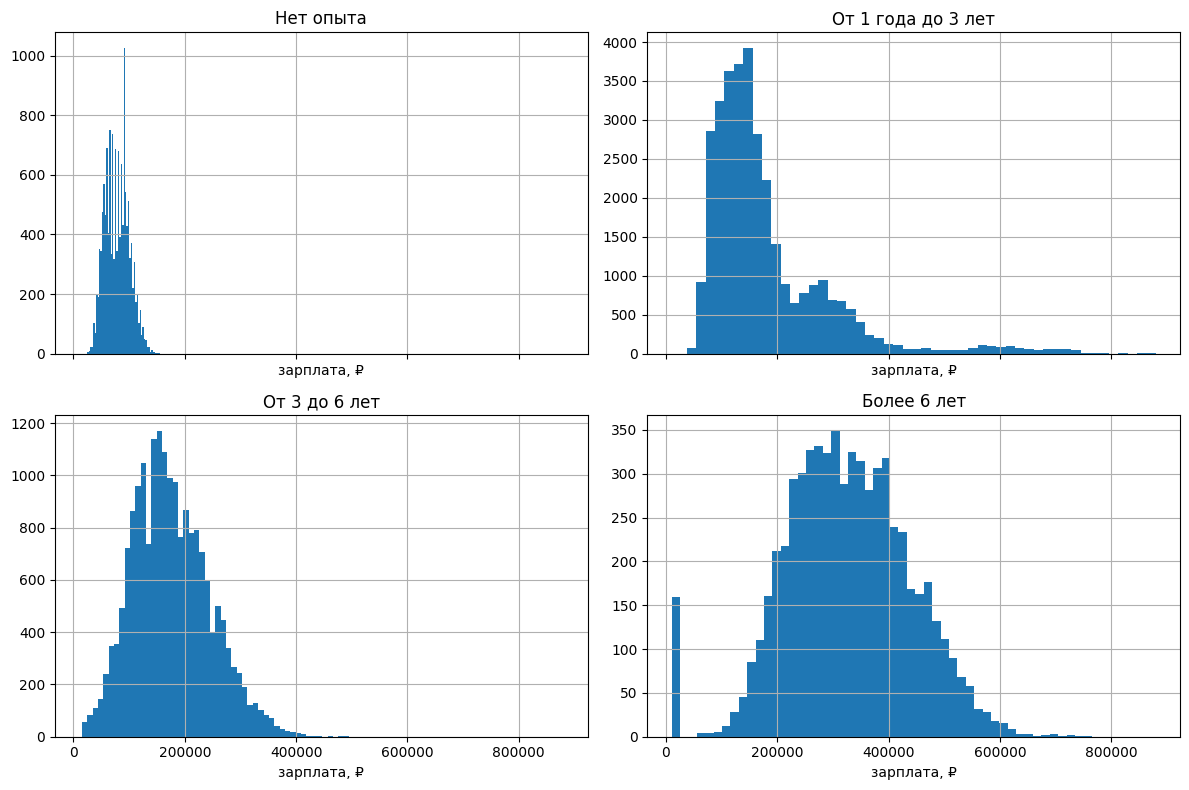

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, exp in zip(axes.flat, order):
    clean.loc[clean['experience'] == exp, 'salary'].hist(bins=50, ax=ax)
    ax.set_title(exp)
    ax.set_xlabel('зарплата, ₽')
plt.tight_layout()



In [ ]:
sen = clean[clean['experience'] == 'Более 6 лет']
sen[sen['salary'] < 60_000][['salary_from','salary_to','salary']].value_counts()

,,,count
salary_from,salary_to,salary,
9000.0,11000.0,10000.0,86
10000.0,12000.0,11000.0,73


In [ ]:
mid = clean[(clean['experience'] == 'От 1 года до 3 лет')]
for lo_, hi_ in [(250_000, 400_000), (400_000, 900_000)]:
    part = mid[mid['salary'].between(lo_, hi_)]
    print(f'{lo_}–{hi_}: {len(part)} строк')
    print(part['city'].value_counts().head(3))
    print(part['employment_type'].value_counts().head(3), '\n')

250000–400000: 5052 строк
city
Москва             3650
Санкт-Петербург    1010
Екатеринбург        112
Name: count, dtype: int64
employment_type
Полная занятость    3531
Удалённая работа     993
Стажировка           273
Name: count, dtype: int64 

400000–900000: 1435 строк
city
Москва             834
Санкт-Петербург    344
Екатеринбург        99
Name: count, dtype: int64
employment_type
Полная занятость    1002
Удалённая работа     282
Стажировка            80
Name: count, dtype: int64 



In [ ]:
lo, hi = 10_000, 1_000_000
clean = df[df['salary'].between(lo, hi)].copy()

bad_senior = (clean['experience'] == 'Более 6 лет') & (clean['salary'] < 60_000)
bad_junior = (clean['experience'] == 'От 1 года до 3 лет') & (clean['salary'] > 400_000)

print('сеньоры:', bad_senior.sum(), ' хвост 1–3:', bad_junior.sum())
clean = clean[~bad_senior & ~bad_junior].copy()
print('итого строк:', len(clean))

сеньоры: 159  хвост 1–3: 1411
итого строк: 71009


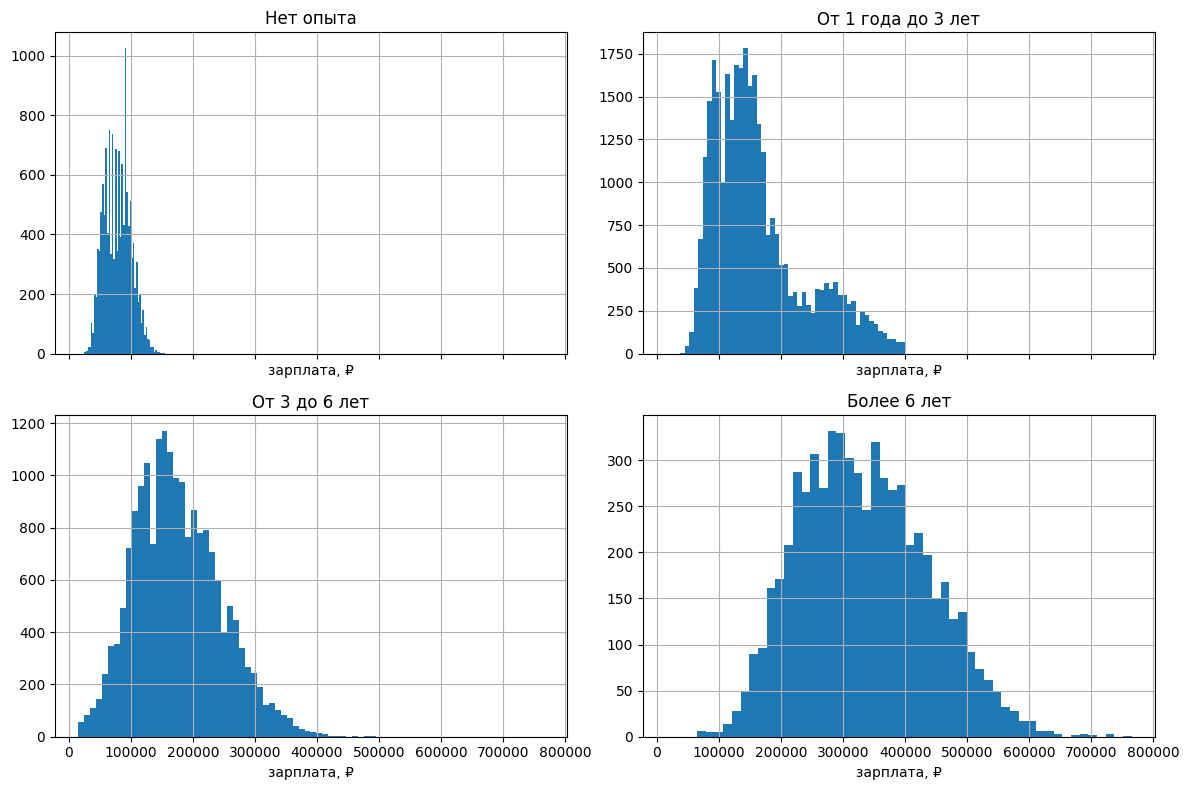

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, exp in zip(axes.flat, order):
    clean.loc[clean['experience'] == exp, 'salary'].hist(bins=50, ax=ax)
    ax.set_title(exp)
    ax.set_xlabel('зарплата, ₽')
plt.tight_layout()


In [ ]:
def calc_stats(data):
    return data.groupby('experience', observed=True)['salary'].agg(
        среднее='mean',
        медиана='median',
        std='std',
        p25=lambda s: s.quantile(0.25),
        p75=lambda s: s.quantile(0.75),
        n='count',
    ).round(0)

stats_clean = calc_stats(clean)
stats_clean

,среднее,медиана,std,p25,p75,n
experience,,,,,,
Нет опыта,78596.0,77500.0,21338.0,60000.0,95000.0,13910
От 1 года до 3 лет,163221.0,145000.0,74471.0,107500.0,192500.0,31826
От 3 до 6 лет,175564.0,167500.0,69153.0,125000.0,220000.0,19068
Более 6 лет,333409.0,327500.0,103620.0,255000.0,405000.0,6205


In [ ]:

skew_clean = clean.groupby('experience', observed=True)['salary'].skew().round(2)

pd.DataFrame({'после очистки': skew_clean})

,после очистки
experience,
Нет опыта,0.24
От 1 года до 3 лет,1.05
От 3 до 6 лет,0.44
Более 6 лет,0.33


In [ ]:
b3 = stats_clean[['медиана','std', 'p25', 'p75']].copy()
b3['IQR'] = b3['p75'] - b3['p25']
b3[['медиана','std', 'p25', 'p75', 'IQR']]

,медиана,std,p25,p75,IQR
experience,,,,,
Нет опыта,77500.0,21338.0,60000.0,95000.0,35000.0
От 1 года до 3 лет,145000.0,74471.0,107500.0,192500.0,85000.0
От 3 до 6 лет,167500.0,69153.0,125000.0,220000.0,95000.0
Более 6 лет,327500.0,103620.0,255000.0,405000.0,150000.0


In [ ]:
sen = clean[clean['experience'] == 'Более 6 лет']

def spread(data, by):
    g = data.groupby(by, observed=True)['salary']
    out = g.agg(медиана='median', std='std', n='count')
    out['IQR'] = g.quantile(0.75) - g.quantile(0.25)
    return out.round(0).sort_values('медиана', ascending=False)
spread(sen, 'employment_type')

,медиана,std,n,IQR
employment_type,,,,
Удалённая работа,330000.0,102924.0,2459,148750.0
Частичная занятость,328750.0,104310.0,316,150000.0
Полная занятость,325000.0,104055.0,3430,150000.0


In [ ]:
sen = clean[clean['experience'] == 'Более 6 лет']

def spread(data, by):
    g = data.groupby(by, observed=True)['salary']
    out = g.agg(медиана='median', std='std', n='count')
    out['IQR'] = g.quantile(0.75) - g.quantile(0.25)
    return out.round(0).sort_values('медиана', ascending=False)

spread(sen, 'city')

,медиана,std,n,IQR
city,,,,
Москва,397500.0,90060.0,2765,122500.0
Санкт-Петербург,340000.0,75314.0,1221,102500.0
Новосибирск,255000.0,60678.0,612,87500.0
Екатеринбург,248750.0,62432.0,636,85625.0
Казань,237500.0,55154.0,573,72500.0
Нижний Новгород,235000.0,52922.0,398,72500.0
